In [2]:
#import py3Dmol
import MDAnalysis as mda
import numpy as np
#import pandas as pd
#u=mda.Universe("step4.1_equilibration.gro","final_production.xtc")
#from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
#u=mda.Universe("protein_ligand.gro","final_production.xtc")
import MDAnalysis as mda
from MDAnalysis.analysis import distances
#from sklearn.cluster import KMeans
#from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import argparse
import random
#from torchvision import datasets, t:wransforms
from torch.utils.data.sampler import SubsetRandomSampler
import torch.utils.data
from scipy.io import loadmat
from backend_GMVAE.backend_GMVAE import GMVAE
import matplotlib.pyplot as plt
import os
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dr,num):
    # Load the topology and trajectory files
    os.chdir(dr)
    current_working_directory=os.getcwd()
    u = mda.Universe(topology_file, trajectory_file)

    # Select the protein residues and ligand atoms
    protein_residues = u.select_atoms(protein_selection)
    ligand_atoms = u.select_atoms(ligand_selection)

    # Create an empty list to store the distances
    num_residues=len(protein_residues)
    avg_distance=np.zeros(num_residues)
    v=0
    # Iterate over all frames in the trajectory
    for ts in u.trajectory:
        # Calculate distances between protein residues and ligand atoms
        dist = distances.distance_array(protein_residues.positions, ligand_atoms.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])

        # Average the distances for each residue
        avg_dist_per_residue = dist.mean(axis=1)

        # Add the average distances to the overall list
        avg_distance=np.add(avg_distance,avg_dist_per_residue)
        v=v+1
        if v>num:
            break
    # Calculate the overall average distance
    average_distance = avg_distance

    return average_distance

topology_file = 'step4.1_equilibration.gro'
trajectory_file = 'step5_production.xtc'
new_topology_file = 'step4.1_equilibration.gro'
trajectory_file = 'step5_production.xtc'
protein_selection = 'name CA and protein'  # Atom selection for the protein residues
ligand_selection = 'resname BMANA'  # Atom selection for the ligand
dhexa1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/hexamana/correct_set/h_109/gromacs"
nhexa1=7500
dhexa2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/hexamana/correct_set/no_h_109/gromacs"
nhexa2=7500
dHF1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/H221F_hexamana/correct_set/h_109/gromacs"
nHF1=7500
dHF2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/H221F_hexamana/correct_set/no_h_109/gromacs"
nHF2=7500
dRL1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/R312L_hexamana/correct_set/h_109/gromacs"
nRL1=7500
dRL2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/R312L_hexamana/correct_set/no_h_109/gromacs"
nRL2=7500
average_hexa1 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dhexa1,nhexa1)
average_hexa2 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dhexa2,nhexa2)
average_HF1 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dHF1,nHF1)
average_HF2 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dHF2,nHF2)
average_RL1 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dRL1,nRL1)
average_RL2 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dRL2,nRL2)
matrices = [average_hexa1,
            average_hexa2,
            average_HF1,
            average_HF2,
            average_RL1,
            average_RL2]
#matrices=[average_MMMM2]
# Initialize the result matrix
result = np.zeros_like(matrices[0])

# Add the matrices
for matrix in matrices:
    result = np.add(result, matrix)
#result=result/nMMMM2
result=result/(nhexa1+nhexa2+nHF1+nHF2+nRL1+nRL2)
def standardize_columns(matrix):
    mean = np.max(matrix, axis=0)
    std = np.min(matrix, axis=0)
    standardized_matrix = (matrix - std) / (mean-std)
    return standardized_matrix


def find_elements_less_than(arr, threshold):
    indices = np.where(arr < threshold)[0]
    elements = arr[indices]
    return indices, elements

# Example usage
threshold_value = 25
print (result)
indices, elements = find_elements_less_than(result, threshold_value)
print("Indices:", indices)
print("Elements:", elements)

sel = f"name CA and resid {' '.join(map(str, indices))}"
MMMM_1="resname BMANA and resid 1"
MMMM_2="resname BMANA and resid 2"
MMMM_3="resname BMANA and resid 3"
MMMM_4="resname BMANA and resid 4"
MMMM_5="resname BMANA and resid 5"
MMMM_6="resname BMANA and resid 6"
structure="step4.1_equilibration.gro"
trajectory="step5_production.xtc"
data=[]
#print ("yes")
def combined_func(selection,selection_1, selection_2, selection_3, selection_4, selection_5, selection_6, structure, trajectory, dr, num,data):
    os.chdir(dr)
    current_working_directory=os.getcwd()
    u = mda.Universe(topology_file, trajectory_file)
    selection=u.select_atoms(selection)
    selection_1=u.select_atoms(selection_1)
    selection_2=u.select_atoms(selection_2)
    selection_3=u.select_atoms(selection_3)
    selection_4=u.select_atoms(selection_4)
    selection_5=u.select_atoms(selection_5)
    selection_6=u.select_atoms(selection_6)
    v=0
    for ts in u.trajectory:
        # Calculate distances between protein residues and ligand atoms
        dist_1 = distances.distance_array(selection.positions, selection_1.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_2 = distances.distance_array(selection.positions, selection_2.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_3 = distances.distance_array(selection.positions, selection_3.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_4 = distances.distance_array(selection.positions, selection_4.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_5 = distances.distance_array(selection.positions, selection_5.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_6 = distances.distance_array(selection.positions, selection_6.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        avg_dist_per_residue_1 = dist_1.mean(axis=1)
        avg_dist_per_residue_2 = dist_2.mean(axis=1)
        avg_dist_per_residue_3 = dist_3.mean(axis=1)
        avg_dist_per_residue_4 = dist_4.mean(axis=1)
        avg_dist_per_residue_5 = dist_5.mean(axis=1)
        avg_dist_per_residue_6 = dist_6.mean(axis=1)
        final_array=np.concatenate((avg_dist_per_residue_1, avg_dist_per_residue_2, avg_dist_per_residue_3, avg_dist_per_residue_4, avg_dist_per_residue_5, avg_dist_per_residue_6 ))
        data.append(final_array)
        v=v+1
        if (v>num):
            break
    return data
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dhexa1,nhexa1,data)
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dhexa2,nhexa2,data)
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dHF1,nHF1,data)
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dHF2,nHF2,data)
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dRL1,nRL1,data)
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dRL2,nRL2,data)
combined_data=np.stack(data,axis=0)
print ("yes")
print(combined_data.shape)
combined_data = standardize_columns(combined_data)
parser = argparse.ArgumentParser(description='PyTorch Implementation of DGM Clustering')

## Used only in notebooks
parser.add_argument('-f', '--file', help='Path for input file. First line should contain number of lines to search in')

## Dataset
parser.add_argument('--seed', type=int, default=1, help='random seed (default: 1)')

## GPU
parser.add_argument('--cuda', type=int, default=1, help='use of cuda (default: 1)')
parser.add_argument('--gpuID', type=int, default=0, help='set gpu id to use (default: 0)')

## Training
parser.add_argument('--epochs', type=int, default=100, help='number of total epochs to run (default: 200)')
parser.add_argument('--batch_size', default=64, type=int, help='mini-batch size (default: 64)')
parser.add_argument('--batch_size_val', default=200, type=int, help='mini-batch size of validation (default: 200)')
parser.add_argument('--learning_rate', default=1e-4, type=float, help='learning rate (default: 0.001)')
parser.add_argument('--decay_epoch', default=-1, type=int, help='Reduces the learning rate every decay_epoch')
parser.add_argument('--lr_decay', default=0.5, type=float, help='Learning rate decay for training (default: 0.5)')

## Architecture
parser.add_argument('--num_classes', type=int, default=5, help='number of classes (default: 10)')
parser.add_argument('--gaussian_size', default=64, type=int, help='gaussian size (default: 64)')
parser.add_argument('--input_size', default=combined_data.shape[1], type=int, help='input size (default: 784)')
parser.add_argument('--train_proportion', default=1.0, type=float, help='proportion of examples to consider for training only (default: 1.0)')


## Gumbel parameters
parser.add_argument('--init_temp', default=1.0, type=float, help='Initial temperature used in gumbel-softmax (recommended 0.5-1.0, default:1.0)')
parser.add_argument('--decay_temp', default=1, type=int, help='Set 1 to decay gumbel temperature at every epoch (default: 1)')
parser.add_argument('--hard_gumbel', default=0, type=int, help='Set 1 to use the hard version of gumbel-softmax (default: 1)')
parser.add_argument('--min_temp', default=0.5, type=float, help='Minimum temperature of gumbel-softmax after annealing (default: 0.5)' )
parser.add_argument('--decay_temp_rate', default=0.013862944, type=float, help='Temperature decay rate at every epoch (default: 0.013862944)')

## Loss function parameters
parser.add_argument('--w_gauss', default=2, type=float, help='weight of gaussian loss (default: 1)')
parser.add_argument('--w_categ', default=1, type=float, help='weight of categorical loss (default: 1)')
parser.add_argument('--w_rec', default=1, type=float, help='weight of reconstruction loss (default: 1)')
parser.add_argument('--rec_type', type=str, choices=['bce', 'mse'],default='bce', help='desired reconstruction loss function (default: bce)')
#combined_data=(combined_data - np.min(combined_data)) / (np.max(combined_data)-np.min(combined_data))
parser.add_argument('--verbose', default=1, type=int, help='print extra information at every epoch.(default: 0)')

args = parser.parse_args()
## Random Seed
SEED = args.seed
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if args.cuda:
  torch.cuda.manual_seed(SEED)
def partition_dataset(n, proportion=0.8):
  train_num = int(n * proportion)
  indices = np.random.permutation(n)
  train_indices, val_indices = indices[:train_num], indices[train_num:]
  return train_indices, val_indices
train_dataset=combined_data
test_dataset=combined_data
if args.train_proportion == 1.0:
  # we use all train dataset without partitioning
  train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=args.batch_size, shuffle=True)
  test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=args.batch_size_val, shuffle=False)
  val_loader = test_loader
else:
  # partition dataset according to train_proportion
  train_indices, val_indices = partition_dataset(len(train_dataset), args.train_proportion)
  # create data loaders for train, validation and test datasets
  train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=args.batch_size, sampler=SubsetRandomSampler(train_indices))
  val_loader = torch.utils.data.DataLoader(train_dataset, batch_size=args.batch_size_val, sampler=SubsetRandomSampler(val_indices))
  test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=args.batch_size_val, shuffle=False)
gmvae = GMVAE(args)
history_loss = gmvae.train(train_loader,val_loader)
test_loss,recon_test,gauss_test,cat_test, labels_test=gmvae.test(test_loader)
print (labels_test)
np.save("labels_test.npy",labels_test)

/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


KeyboardInterrupt: 

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


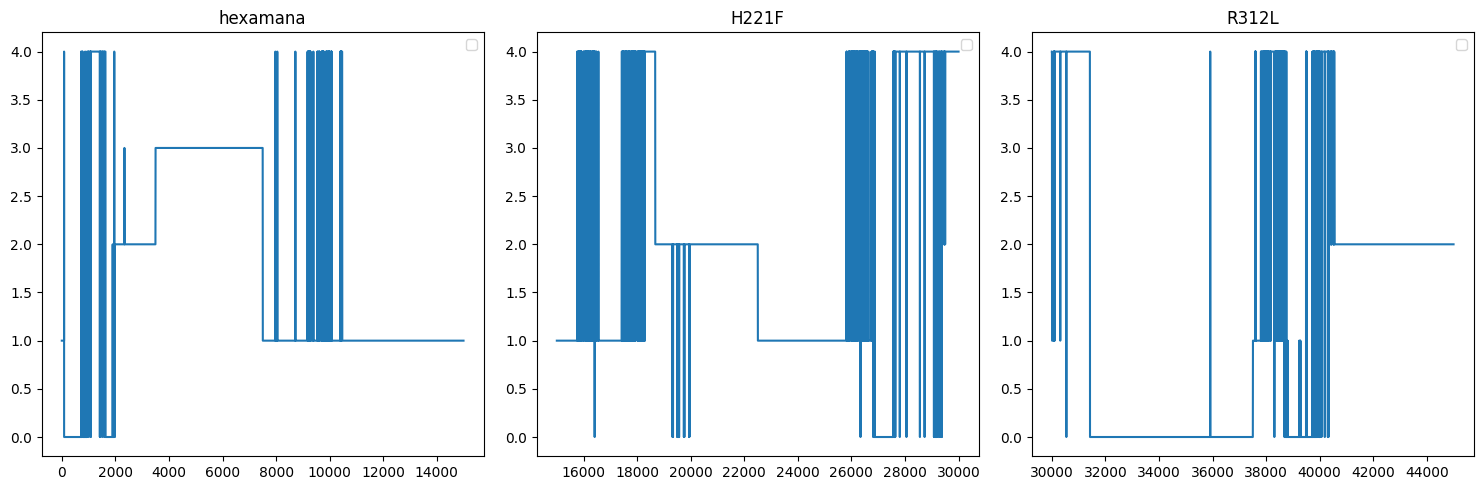

In [6]:
import os
import matplotlib.pyplot as plt
import numpy as np
os.chdir("/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations")
dhexa1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/hexamana/correct_set/h_109/gromacs"
nhexa1=7500
dhexa2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/hexamana/correct_set/no_h_109/gromacs"
nhexa2=7500
dHF1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/H221F_hexamana/correct_set/h_109/gromacs"
nHF1=7500
dHF2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/H221F_hexamana/correct_set/no_h_109/gromacs"
nHF2=7500
dRL1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/R312L_hexamana/correct_set/h_109/gromacs"
nRL1=7500
dRL2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/R312L_hexamana/correct_set/no_h_109/gromacs"
nRL2=7500
#kmeans=KMeans(n_clusters=4)ggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggg
#clusters = kmeans.fit(combined_data
labels_test=np.load("labels_test.npy")
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
x=[]
j=0
for i in range (0,(nhexa1+nhexa2+nHF1+nHF2+nRL1+nRL2)):

    j=j+1
    x.append(i)
# Plot in the first subplot
axs[0].plot(x[0:(nhexa1+nhexa2)], labels_test[0:(nhexa1+nhexa2)])
axs[0].set_title('hexamana')
axs[0].legend()

# Plot in the second subplot
axs[1].plot(x[(nhexa1+nhexa2):(nhexa1+nhexa2+nHF1+nHF2)], labels_test[(nhexa1+nhexa2):(nhexa1+nhexa2+nHF1+nHF2)])
axs[1].set_title('H221F')
axs[1].legend()

# Plot in the third subplot
axs[2].plot(x[(nhexa1+nhexa2+nHF1+nHF2):(nhexa1+nhexa2+nHF1+nHF2+nRL1+nRL2)], labels_test[(nhexa1+nhexa2+nHF1+nHF2):(nhexa1+nhexa2+nHF1+nHF2+nRL1+nRL2)])
axs[2].set_title('R312L')
axs[2].legend()

# Add space between subplots
plt.tight_layout()

# Add a main title to the entire figure
#plt.suptitle('K-Means')

# Show the plot
#In this example, we use plt.subplots to create a 1x3 grid of subplots within a single figure. We then plot different functions in each subplot using the individual axs objects. The figsize parameter in the plt.subplots function determines the size of the entire figure. The plt.tight_layout() function is used to add spacing between the subplots, and plt.suptitle() adds a main title to the entire figure.
plt.savefig("GMVAE.jpg")
plt.show()

In [12]:
!ls

backend_GMVAE						    slurm-2853978.out
bin							    slurm-2854553.out
charmm-gui-Asp-123					    slurm-2854558.out
charmm-gui-no-Asp					    slurm-2855309.out
cuda-repo-debian11-11-8-local_11.8.0-520.61.05-1_amd64.deb  slurm-2855541.out
cuda-repo-rhel7-11-8-local-11.8.0_520.61.05-1.x86_64.rpm    slurm-2856596.out
dyn.csh							    slurm-2856618.out
dysamplegeneration.sh					    slurm-2856627.out
final_production.xtc					    slurm-2856651.out
first-dyn.csh						    slurm-2856657.out
fourha.pdb						    slurm-2856658.out
GMVAE.py						    slurm-2856666.out
gromacs-2019.4						    slurm-2856681.out
H221F_fourha						    slurm-2856814.out
H221F_hexamana						    slurm-2859167.out
H221F_tetraha						    slurm-2859190.out
hexamana						    slurm-2859211.out
include							    slurm-2859462.out
lib64							    slurm-2860484.out
miniconda						    slurm-2860485.out
miniconda.sh						    slurm-2860486.out
ML.yml							    slurm-2860627.out
protein_ligand.gro					    slurm-2860631.out
py3.py		

In [1]:
import MDAnalysis as mda
import numpy as np
#import pandas as pd
#u=mda.Universe("step4.1_equilibration.gro","final_production.xtc")
#from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
#u=mda.Universe("protein_ligand.gro","final_production.xtc")
import MDAnalysis as mda
from MDAnalysis.analysis import distances
#from sklearn.cluster import KMeans
#from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import argparse
import random
#from torchvision import datasets, t:wransforms
from torch.utils.data.sampler import SubsetRandomSampler
import torch.utils.data
from scipy.io import loadmat
#from backend_GMVAE.backend_GMVAE import GMVAE
import matplotlib.pyplot as plt
import os
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dr,num):
    # Load the topology and trajectory files
    os.chdir(dr)
    current_working_directory=os.getcwd()
    u = mda.Universe(topology_file, trajectory_file)

    # Select the protein residues and ligand atoms
    protein_residues = u.select_atoms(protein_selection)
    ligand_atoms = u.select_atoms(ligand_selection)

    # Create an empty list to store the distances
    num_residues=len(protein_residues)
    avg_distance=np.zeros(num_residues)
    v=0
    # Iterate over all frames in the trajectory
    for ts in u.trajectory:
        # Calculate distances between protein residues and ligand atoms
        dist = distances.distance_array(protein_residues.positions, ligand_atoms.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])

        # Average the distances for each residue
        avg_dist_per_residue = dist.mean(axis=1)

        # Add the average distances to the overall list
        avg_distance=np.add(avg_distance,avg_dist_per_residue)
        v=v+1
        if v>num:
            break
    # Calculate the overall average distance
    average_distance = avg_distance

    return average_distance

topology_file = 'step4.1_equilibration.gro'
trajectory_file = 'step5_production.xtc'
new_topology_file = 'step4.1_equilibration.gro'
trajectory_file = 'step5_production.xtc'
protein_selection = 'name CA and protein'  # Atom selection for the protein residues
ligand_selection = 'resname BMANA'  # Atom selection for the ligand
dhexa1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/hexamana/correct_set/h_109/gromacs"
nhexa1=7500
dhexa2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/hexamana/correct_set/no_h_109/gromacs"
nhexa2=7500
dHF1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/H221F_hexamana/correct_set/h_109/gromacs"
nHF1=7500
dHF2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/H221F_hexamana/correct_set/no_h_109/gromacs"
nHF2=7500
dRL1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/R312L_hexamana/correct_set/h_109/gromacs"
nRL1=7500
dRL2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/R312L_hexamana/correct_set/no_h_109/gromacs"
nRL2=7500
average_hexa1 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dhexa1,nhexa1)
average_hexa2 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dhexa2,nhexa2)
average_HF1 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dHF1,nHF1)
average_HF2 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dHF2,nHF2)
average_RL1 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dRL1,nRL1)
average_RL2 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dRL2,nRL2)
matrices = [average_hexa1,
            average_hexa2,
            average_HF1,
            average_HF2,
            average_RL1,
            average_RL2]
#matrices=[average_MMMM2]
# Initialize the result matrix
result = np.zeros_like(matrices[0])

# Add the matrices
for matrix in matrices:
    result = np.add(result, matrix)
#result=result/nMMMM2
result=result/(nhexa1+nhexa2+nHF1+nHF2+nRL1+nRL2)
def standardize_columns(matrix):
    matrix_max = np.max(matrix, axis=0)
    matrix_min = np.min(matrix, axis=0)
    standardized_matrix = (matrix - mean) / std
    return standardized_matrix



def find_elements_less_than(arr, threshold):
    indices = np.where(arr < threshold)[0]
    elements = arr[indices]
    return indices, elements

# Example usage
threshold_value = 25
print (result)
indices, elements = find_elements_less_than(result, threshold_value)
print("Indices:", indices)
print("Elements:", elements)

sel = f"name CA and resid {' '.join(map(str, indices))}"
MMMM_1="resname BMANA and resid 1"
MMMM_2="resname BMANA and resid 2"
MMMM_3="resname BMANA and resid 3"
MMMM_4="resname BMANA and resid 4"
MMMM_5="resname BMANA and resid 5"
MMMM_6="resname BMANA and resid 6"
structure="step4.1_equilibration.gro"
trajectory="step5_production.xtc"
data=[]
#print ("yes")
def combined_func(selection,selection_1, selection_2, selection_3, selection_4, selection_5, selection_6, structure, trajectory, dr, num,data):
    os.chdir(dr)
    current_working_directory=os.getcwd()
    u = mda.Universe(topology_file, trajectory_file)
    selection=u.select_atoms(selection)
    selection_1=u.select_atoms(selection_1)
    selection_2=u.select_atoms(selection_2)
    selection_3=u.select_atoms(selection_3)
    selection_4=u.select_atoms(selection_4)
    selection_5=u.select_atoms(selection_5)
    selection_6=u.select_atoms(selection_6)
    v=0
    for ts in u.trajectory:
        # Calculate distances between protein residues and ligand atoms
        dist_1 = distances.distance_array(selection.positions, selection_1.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_2 = distances.distance_array(selection.positions, selection_2.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_3 = distances.distance_array(selection.positions, selection_3.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_4 = distances.distance_array(selection.positions, selection_4.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_5 = distances.distance_array(selection.positions, selection_5.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_6 = distances.distance_array(selection.positions, selection_6.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        avg_dist_per_residue_1 = dist_1.mean(axis=1)
        avg_dist_per_residue_2 = dist_2.mean(axis=1)
        avg_dist_per_residue_3 = dist_3.mean(axis=1)
        avg_dist_per_residue_4 = dist_4.mean(axis=1)
        avg_dist_per_residue_5 = dist_5.mean(axis=1)
        avg_dist_per_residue_6 = dist_6.mean(axis=1)
        final_array=np.concatenate((avg_dist_per_residue_1, avg_dist_per_residue_2, avg_dist_per_residue_3, avg_dist_per_residue_4, avg_dist_per_residue_5, avg_dist_per_residue_6 ))
        data.append(final_array)
        v=v+1
        if (v>num):
            break
    return data
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dhexa1,nhexa1,data)
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dhexa2,nhexa2,data)
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dHF1,nHF1,data)
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dHF2,nHF2,data)
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dRL1,nRL1,data)
data=combined_func(sel,MMMM_1,MMMM_2,MMMM_3,MMMM_4,MMMM_5,MMMM_6,structure,trajectory,dRL2,nRL2,data)
combined_data=np.stack(data,axis=0)
print ("yes")
print(combined_data.shape)

def silly(k,combined_data):
    kmeans=KMeans(n_clusters=k)
    kmeans.fit(combined_data)
    label=kmeans.predict(combined_data)
    sc=silhouette_score(combined_data, label)
    print("Silhouette Score for {}:{}".format(k,sc))
    return sc
no=[]
score=[]
for j in range (2,40):
    sc=silly(j,combined_data)
    score.append(sc)
    no.append(j)

max_element=max(score)
max_index=score.index(max_element)
m_index=max_index+2
kmeans=KMeans(n_clusters=m_index)
clusters = kmeans.fit(combined_data)


    


/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[40.48105729 39.05980607 37.92836783 37.52906466 35.01713436 33.33814393
 33.32122978 31.22535833 28.93155315 28.17155492 25.63070359 22.98384422
 22.2340424  19.99692693 19.48347173 17.7186037  18.30685008 18.41898574
 18.95314686 18.44458054 17.88012436 18.23400745 18.57912002 19.87926739
 20.66229694 20.53837056 22.71457047 23.9438643  25.087432   22.60933073
 21.42221609 24.09325442 24.14065484 21.54982646 22.79801845 25.41438774
 24.15019817 22.98925784 25.59935935 27.63241375 25.57855428 24.882323
 28.08601952 28.97998208 27.11676662 28.37274869 31.3599263  31.43608187
 30.4036029  32.68328325 34.86741818 34.40361393 34.46533887 36.8321503
 37.85402066 37.41386962 38.10095968 39.6400771  40.19698923 40.25532491
 40.57053157 40.27372238 38.41202126 38.14286996 39.20796504 37.89579291
 35.53040889 36.52179688 37.33819744 34.68212608 33.22445834 35.58793082
 35.51205556 32.42031402 33.01433333 35.5502766  33.8732833  31.44146594
 29.06594795 25.84399499 26.60657144 26.37787834 24.35

/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Silhouette Score for 2:0.4344116606673813


/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Silhouette Score for 3:0.3813635970513439


... (69 outputs left out)

Silhouette Score for 38:0.2774986181811728


/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Silhouette Score for 39:0.27635153431820786


/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


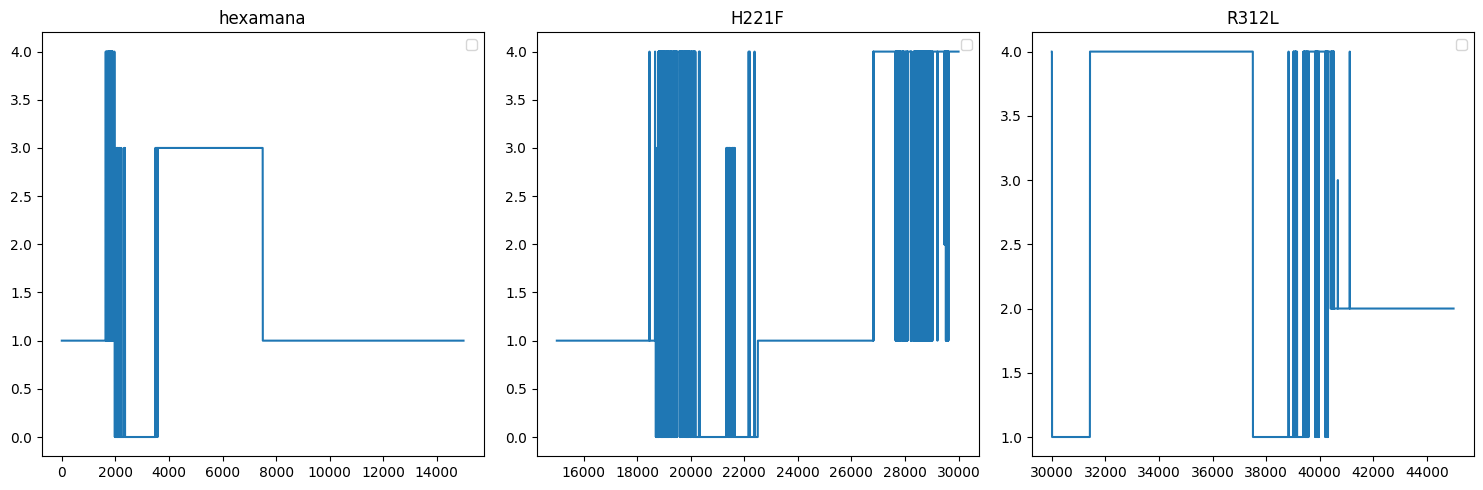

In [4]:
os.chdir("/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations")
#kmeans=KMeans(n_clusters=4)
#clusters = kmeans.fit(combined_data)
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
x=[]
for i in range (0,(nhexa1+nhexa2+nHF1+nHF2+nRL1+nRL2)):

    j=j+1
    x.append(i)
# Plot in the first subplot
axs[0].plot(x[0:(nhexa1+nhexa2)], clusters.labels_[0:(nhexa1+nhexa2)])
axs[0].set_title('hexamana')
axs[0].legend()

# Plot in the second subplot
axs[1].plot(x[(nhexa1+nhexa2):(nhexa1+nhexa2+nHF1+nHF2)], clusters.labels_[(nhexa1+nhexa2):(nhexa1+nhexa2+nHF1+nHF2)])
axs[1].set_title('H221F')
axs[1].legend()

# Plot in the third subplot
axs[2].plot(x[(nhexa1+nhexa2+nHF1+nHF2):(nhexa1+nhexa2+nHF1+nHF2+nRL1+nRL2)], clusters.labels_[(nhexa1+nhexa2+nHF1+nHF2):(nhexa1+nhexa2+nHF1+nHF2+nRL1+nRL2)])
axs[2].set_title('R312L')
axs[2].legend()

# Add space between subplots
plt.tight_layout()

# Add a main title to the entire figure
#plt.suptitle('K-Means')

# Show the plot
#In this example, we use plt.subplots to create a 1x3 grid of subplots within a single figure. We then plot different functions in each subplot using the individual axs objects. The figsize parameter in the plt.subplots function determines the size of the entire figure. The plt.tight_layout() function is used to add spacing between the subplots, and plt.suptitle() adds a main title to the entire figure.
plt.savefig("K-Means.jpg")
plt.show()



